# Working of Flash Memory: Principle, Architecture and Operation
**CSE 305 Computer Organization and Architecture, SRM University-AP** (Unit 4: Memory System)

This notebook explains and simulates how flash memory works. Run the cells from top to bottom (Runtime > Run all).

## Where this project fits in the syllabus (Unit 4: Memory System)
| Syllabus topic | How the project covers it |
|---|---|
| Memory hierarchy, Memory technology | Flash is non-volatile semiconductor memory. Part A shows how one cell stores a bit. |
| Speed, size and cost; RAM, ROM | Flash is an EEPROM-type ROM that can be rewritten in blocks. Part E compares NAND and NOR on speed, density and cost. |
| Virtual memory, Memory management requirements | The controller's mapping table translates logical addresses to physical pages, like a page table (Part C). |
| Secondary storage devices | NAND flash is the storage in SSDs, USB drives and SD cards. Part B and C show pages, blocks and how they are read, written and erased. |

## How the notebook is organised
| Part | Title word | What you will see |
|---|---|---|
| A | **Principle** | How a floating-gate cell stores a bit, and the voltages used to read, program and erase it |
| B | **Architecture** | NOR vs NAND cell arrays, chip hierarchy (block, page), controller block diagram |
| C | **Operation** | Read, program and erase rules, address mapping, garbage collection, wear leveling, NOR byte access |
| D | Front end | Drawing functions and an interactive control panel |
| E | Comparison | NAND vs NOR table, viva questions and conclusion |

## Setup

In [1]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pandas as pd
print("Libraries ready")

Libraries ready


# Part A: Principle
## The floating-gate transistor
A flash cell is a transistor with an extra **floating gate** trapped in insulating oxide, between the control gate and the channel.

- **No charge** on the floating gate: the transistor turns on at a **low** threshold voltage (Vt). We read this as **1** (erased).
- **Electrons trapped** on the floating gate: the transistor needs a **higher** Vt to turn on. We read this as **0** (programmed).

**Three operations:**
- **Read**: apply a reference voltage Vread between the two Vt values. If current flows, the cell is 1. If not, it is 0.
- **Program**: apply a high voltage on the control gate. Electrons enter the floating gate (hot-electron injection in NOR, Fowler-Nordheim tunnelling in NAND), so Vt rises.
- **Erase**: apply a high voltage on the substrate. Electrons tunnel out of the floating gate and Vt drops. This acts on a whole block or sector at once, which is why erase is coarse.

In [2]:
class FloatingGateCell:
    ERASED_VT, PROGRAMMED_VT, VREAD = 1.0, 4.0, 2.5      # illustrative volts

    def __init__(self):
        self.vt = self.ERASED_VT          # no charge on the floating gate

    def program(self):
        self.vt = self.PROGRAMMED_VT      # electrons injected: Vt goes up

    def erase(self):
        self.vt = self.ERASED_VT          # electrons removed: Vt goes down

    def read(self):
        conducts = self.VREAD > self.vt   # does the cell turn on at Vread?
        return 1 if conducts else 0

cell = FloatingGateCell()
print("Fresh cell: Vt =", cell.vt, "V, reads", cell.read())
cell.program()
print("After program: Vt =", cell.vt, "V, reads", cell.read())
cell.erase()
print("After erase: Vt =", cell.vt, "V, reads", cell.read())

Fresh cell: Vt = 1.0 V, reads 1
After program: Vt = 4.0 V, reads 0
After erase: Vt = 1.0 V, reads 1


## Voltages used in each NAND operation
The voltages are typical approximations and differ between devices.

| Operation | Selected word line | Other word lines | Substrate | Result |
|---|---|---|---|---|
| Read | Vread (low, between the two Vt values) | Vpass (about 5 to 6 V) so they conduct | 0 V | Sense whether the string conducts |
| Program | Vpgm (about 18 to 20 V) | Vpass (about 10 V) | 0 V | Electrons tunnel into the floating gate |
| Erase (whole block) | 0 V | 0 V | About 20 V | Electrons tunnel out of every cell in the block |

# Part B: Architecture
## Cell array: NOR (parallel) vs NAND (series)
How the cells are wired decides everything else: access speed, density and erase size.

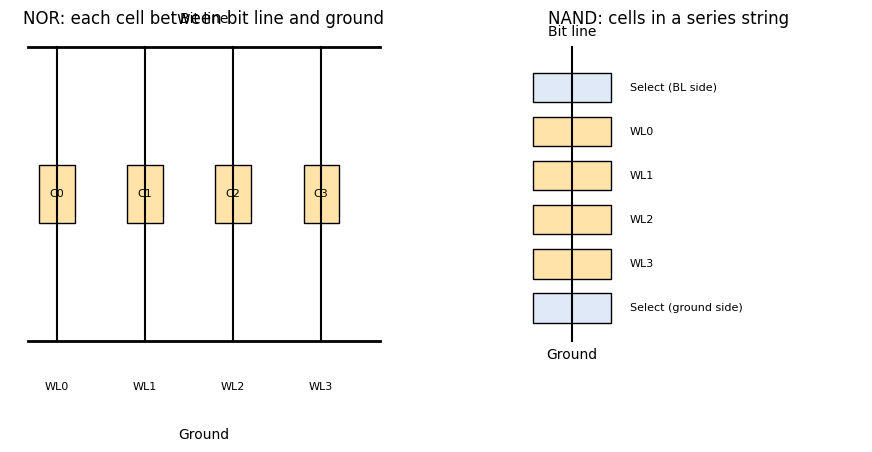

NOR: any cell can be read alone. NAND: one string conducts only if every other cell in it is switched on.


In [3]:
def draw_arrays():
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
    a.set_title("NOR: each cell between bit line and ground")
    a.plot([-0.5, 5.5], [3, 3], "k", lw=2); a.plot([-0.5, 5.5], [0, 0], "k", lw=2)
    for i in range(4):
        x = i * 1.5
        a.plot([x, x], [0, 3], "k")
        a.add_patch(Rectangle((x - .3, 1.2), .6, .6, fc="#ffe3a8", ec="k"))
        a.text(x, 1.5, f"C{i}", ha="center", va="center", fontsize=8)
        a.text(x, -.5, f"WL{i}", ha="center", fontsize=8)
    a.text(2.5, 3.25, "Bit line", ha="center"); a.text(2.5, -1, "Ground", ha="center"); a.axis("off")
    b.set_title("NAND: cells in a series string")
    b.plot([1, 1], [-.5, 7.5], "k")
    names = ["Select (BL side)", "WL0", "WL1", "WL2", "WL3", "Select (ground side)"]
    for i, nm in enumerate(names):
        y = 6 - i * 1.2
        b.add_patch(Rectangle((.6, y), .8, .8, fc="#ffe3a8" if "WL" in nm else "#dfe9f7", ec="k"))
        b.text(1.6, y + .4, nm, va="center", fontsize=8)
    b.text(1, 7.8, "Bit line", ha="center"); b.text(1, -1, "Ground", ha="center")
    b.set_xlim(0, 4); b.axis("off")
    plt.show()

draw_arrays()
print("NOR: any cell can be read alone. NAND: one string conducts only if every other cell in it is switched on.")

## Chip hierarchy and page layout
A NAND chip is organised from big to small: **chip > block > page > cell**. Pages are the unit of read and program. Blocks are the unit of erase. Each page also has a **spare area** that holds the logical address and bad-block marks.

In [4]:
pd.DataFrame({
    "Level": ["Chip", "Block", "Page", "Spare area", "Cell"],
    "What it is": ["The package that holds all the blocks", "Smallest unit that can be erased",
                   "Smallest unit that can be read or programmed", "Extra bytes beside the page data",
                   "One floating-gate transistor"],
    "Typical size (varies by device)": ["Many GB", "64 to 256 pages", "4 to 16 KB",
                                         "A few hundred bytes (logical address, bad-block mark)", "1 bit"],
}).set_index("Level")

,What it is,Typical size (varies by device)
Level,,
Chip,The package that holds all the blocks,Many GB
Block,Smallest unit that can be erased,64 to 256 pages
Page,Smallest unit that can be read or programmed,4 to 16 KB
Spare area,Extra bytes beside the page data,"A few hundred bytes (logical address, bad-bloc..."
Cell,One floating-gate transistor,1 bit


## Controller block diagram
Real flash devices are managed by a controller sitting between the host and the NAND chips. The simulator's classes in Part C play the roles of these blocks.

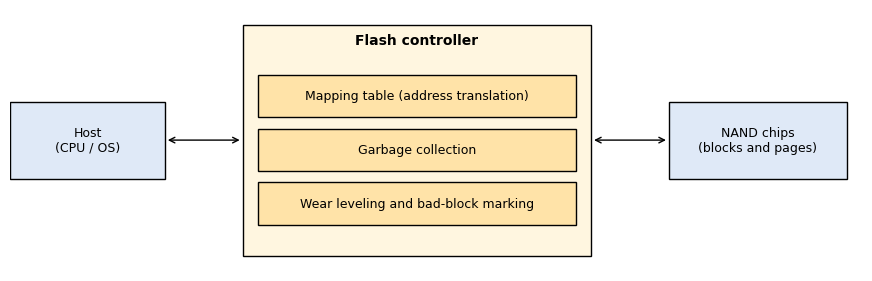

,Class in this notebook
Controller block,
Mapping table,"FTL.map, FTL.write"
Garbage collection,FTLWithGC.garbage_collect
Wear leveling,FTL.pick_free
NAND chips,NANDChip


In [5]:
def draw_controller():
    fig, ax = plt.subplots(figsize=(11, 3.4)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 3.4)
    def box(x, y, w, h, t, c):
        ax.add_patch(Rectangle((x, y), w, h, fc=c, ec="k")); ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=9)
    box(0, 1.2, 2, 1, "Host\n(CPU / OS)", "#dfe9f7")
    box(3, 0.2, 4.5, 3, "", "#fff6e0")
    ax.text(5.25, 2.95, "Flash controller", ha="center", fontsize=10, weight="bold")
    for i, t in enumerate(["Mapping table (address translation)", "Garbage collection", "Wear leveling and bad-block marking"]):
        box(3.2, 2.0 - i * 0.7, 4.1, 0.55, t, "#ffe3a8")
    box(8.5, 1.2, 2.3, 1, "NAND chips\n(blocks and pages)", "#dfe9f7")
    for x0, x1 in [(2, 3), (7.5, 8.5)]:
        ax.annotate("", xy=(x1, 1.7), xytext=(x0, 1.7), arrowprops=dict(arrowstyle="<->"))
    plt.show()

draw_controller()
pd.DataFrame({"Controller block": ["Mapping table", "Garbage collection", "Wear leveling", "NAND chips"],
              "Class in this notebook": ["FTL.map, FTL.write", "FTLWithGC.garbage_collect", "FTL.pick_free", "NANDChip"]}).set_index("Controller block")

# Part C: Operation
The mechanisms below show how reads, writes and erases really work, and how the controller hides the flash rules.

## Mechanism 1, the floating-gate cell
A flash cell stores a bit as **charge on a floating gate**. No charge reads **1** (erased). Trapped electrons raise the threshold voltage and read **0** (programmed).

- **Program** adds charge, so a bit can only change **1 to 0**.
- **Erase** removes charge from a whole group of cells at once (Fowler-Nordheim tunnelling), so every bit returns to **1**.

We model one byte as 8 cells. An erased byte is `0xFF`.

In [6]:
ERASED = 0xFF

class FlashError(Exception):
    """Raised when a command breaks a flash rule."""

def bits(v):
    return format(v, "08b")

def program_byte(old, new):
    """Programming can only clear bits (1 -> 0). Result = what the cells hold."""
    if (old & new) != new:
        raise FlashError(f"Cannot program {bits(new)} over {bits(old)}: needs 0 -> 1. Erase first.")
    return new

# Quick check of the rule
print(bits(program_byte(ERASED, 0b10101010)))
try:
    program_byte(0b10101010, 0b11110000)
except FlashError as e:
    print("Refused:", e)

10101010
Refused: Cannot program 11110000 over 10101010: needs 0 -> 1. Erase first.


## Mechanism 2, the NAND chip
NAND is organised as **blocks of pages**. We **read and program one page at a time**, but we can only **erase a whole block**. Each erase wears the block out; after `endurance` erases it becomes a **bad block**.

Page states: `free` (erased), `valid` (current data), `invalid` (stale copy).

In [7]:
class NANDChip:
    def __init__(self, blocks=6, pages=4, endurance=8):
        self.NB, self.NP, self.endurance = blocks, pages, endurance
        self.data  = [[ERASED] * pages for _ in range(blocks)]
        self.state = [["free"] * pages for _ in range(blocks)]
        self.owner = [[-1] * pages for _ in range(blocks)]     # which LBA lives here
        self.erase_count = [0] * blocks
        self.bad = [False] * blocks
        self.reads = self.programs = self.erases = 0

    def read_page(self, b, p):
        self.reads += 1
        return self.data[b][p]

    def program_page(self, b, p, value, lba=-1):
        if self.bad[b]:
            raise FlashError(f"Block {b} is bad")
        if self.data[b][p] != ERASED:
            raise FlashError(f"Page {b}.{p} is not erased; NAND pages are programmed once per erase")
        self.data[b][p] = program_byte(self.data[b][p], value)
        self.state[b][p] = "valid"
        self.owner[b][p] = lba
        self.programs += 1

    def erase_block(self, b):
        self.data[b] = [ERASED] * self.NP
        self.state[b] = ["free"] * self.NP
        self.owner[b] = [-1] * self.NP
        self.erase_count[b] += 1
        self.erases += 1
        if self.erase_count[b] >= self.endurance:
            self.bad[b] = True

chip = NANDChip()
chip.program_page(0, 0, 0xA5)
print("Page 0.0 =", hex(chip.read_page(0, 0)))

Page 0.0 = 0xa5


## Mechanism 3, address mapping and wear leveling
The host sees ordinary logical addresses (LBA). The controller hides the flash rules:

1. **Mapping table**: LBA to (block, page), like a page table in virtual memory.
2. **Out-of-place update**: a rewrite goes to a new free page and the old page becomes `invalid`.
3. **Wear leveling**: choose the free page in the **least-erased** block, so no block dies early.

This layer is called the Flash Translation Layer (FTL).

In [8]:
class FTL:
    def __init__(self, chip, n_lba=12, wear_leveling=True):
        self.chip, self.n_lba, self.wear_leveling = chip, n_lba, wear_leveling
        self.map = {}                       # LBA -> (block, page)
        self.host_writes = self.copies = self.gc_runs = 0
        self.log = []

    def say(self, msg):
        self.log.append(msg)

    def free_pages(self):
        c = self.chip
        return sum(s == "free" for b in range(c.NB) if not c.bad[b] for s in c.state[b])

    def pick_free(self, exclude=None):
        """Return (block, page) of the next free page, or None."""
        c, best = self.chip, None
        for b in range(c.NB):
            if c.bad[b] or b == exclude or "free" not in c.state[b]:
                continue
            if best is None or (self.wear_leveling and c.erase_count[b] < c.erase_count[best]):
                best = b
            if not self.wear_leveling:
                break                       # first free block wins
        return None if best is None else (best, c.state[best].index("free"))

    def garbage_collect(self):
        raise NotImplementedError("Defined in the next cell")

    def write(self, lba, value):
        if not 0 <= lba < self.n_lba:
            raise FlashError(f"LBA must be 0..{self.n_lba - 1}")
        self.host_writes += 1
        old = self.map.get(lba)
        if old:                                           # out-of-place update
            self.chip.state[old[0]][old[1]] = "invalid"
        if self.free_pages() <= self.chip.NP:             # running low: reclaim space
            self.garbage_collect()
        target = self.pick_free()
        if target is None:
            raise FlashError("Flash is full")
        b, p = target
        self.chip.program_page(b, p, value, lba)
        self.map[lba] = (b, p)
        self.say(f"Write LBA {lba} = 0x{value:02X} -> block {b} page {p}" + (f" (old copy at {old[0]}.{old[1]} now stale)" if old else ""))

    def read(self, lba):
        if lba not in self.map:
            raise FlashError(f"LBA {lba} was never written")
        b, p = self.map[lba]
        v = self.chip.read_page(b, p)
        self.say(f"Read LBA {lba} via map -> {b}.{p} = 0x{v:02X}")
        return v

## Mechanism 4, garbage collection
Stale pages cannot be reused until their **whole block** is erased. Garbage collection:

1. Picks the **victim** block with the most stale pages.
2. **Copies** its valid pages elsewhere.
3. **Erases** the victim block.

In [9]:
class FTLWithGC(FTL):
    def garbage_collect(self):
        c, victim, most = self.chip, None, 0
        for b in range(c.NB):
            if not c.bad[b] and c.state[b].count("invalid") > most:
                victim, most = b, c.state[b].count("invalid")
        if victim is None:
            self.say("GC: no stale pages to reclaim")
            return False
        self.say(f"GC: victim block {victim} ({most} stale pages)")
        for p in range(c.NP):
            if c.state[victim][p] == "valid":
                target = self.pick_free(exclude=victim)
                if target is None:
                    self.say("GC failed: no room to copy")
                    return False
                lba = c.owner[victim][p]
                c.program_page(*target, c.data[victim][p], lba)
                self.map[lba] = target
                self.copies += 1
                self.say(f"  moved LBA {lba} to {target[0]}.{target[1]}")
        c.erase_block(victim)
        self.gc_runs += 1
        self.say(f"GC: erased block {victim} (erase count {c.erase_count[victim]})" + (" -> now BAD" if c.bad[victim] else ""))
        return True

## Mechanism 5, the NOR chip
NOR cells are wired **in parallel**, so every byte has its own path to the bit line:

- **Random read of any byte**, so a CPU can run code straight from flash (**execute in place**).
- **Program one byte at a time** (channel hot-electron injection).
- **Erase a whole sector** (still Fowler-Nordheim tunnelling), and bits still only go 1 to 0 until then.
- No mapping layer is needed, but changing a bit from 0 to 1 costs a sector erase.

Time model: read = 1, byte program = 2, sector erase = 50 units.

In [10]:
class NORChip:
    READ, PROG, ERASE = 1, 2, 50

    def __init__(self, sectors=4, sector_size=8):
        self.S, self.size = sectors, sector_size
        self.data = [ERASED] * (sectors * sector_size)
        self.erase_count = [0] * sectors
        self.reads = self.programs = self.erases = self.time = 0
        self.log = []

    def say(self, m): self.log.append(m)

    def read(self, addr):
        self.reads += 1; self.time += self.READ
        self.say(f"Read byte {addr} directly = 0x{self.data[addr]:02X}")
        return self.data[addr]

    def program(self, addr, value):
        self.data[addr] = program_byte(self.data[addr], value)
        self.programs += 1; self.time += self.PROG
        self.say(f"Programmed byte {addr} = 0x{value:02X} ({bits(value)})")

    def erase_sector(self, sector):
        a = sector * self.size
        self.data[a:a + self.size] = [ERASED] * self.size
        self.erase_count[sector] += 1
        self.erases += 1; self.time += self.ERASE
        self.say(f"Erased sector {sector} (erase count {self.erase_count[sector]})")

    def update(self, addr, value):
        """Safe update: in place if only 1->0 flips are needed, else erase and rewrite the sector."""
        if (self.data[addr] & value) == value:
            self.program(addr, value)
            return
        s = addr // self.size
        a = s * self.size
        keep = self.data[a:a + self.size]
        keep[addr - a] = value
        self.say(f"Update at {addr} needs 0->1: save sector {s}, erase, reprogram")
        self.erase_sector(s)
        for i, v in enumerate(keep):
            if v != ERASED:
                self.program(a + i, v)

    def fetch_sector(self, addr):
        """Execute in place: read a run of bytes directly like instruction fetch."""
        a = (addr // self.size) * self.size
        vals = [self.read(a + i) for i in range(self.size)]
        self.say("XIP fetch: " + " ".join(f"{v:02X}" for v in vals))
        return vals

nor = NORChip()
nor.program(3, 0x3C)
print(hex(nor.read(3)))

0x3c


## Demo of the mechanisms (no front end)
This cell proves each rule with printed output. Good for explaining step by step.

In [11]:
random.seed(42)          # fixed seed so the printed output is repeatable

print("--- NAND rule: a page can only be programmed once per erase ---")
demo = NANDChip()
demo.program_page(0, 0, 0xAA)
try:
    demo.program_page(0, 0, 0x55)
except FlashError as e:
    print("Refused:", e)

print("\n--- Mapping: out-of-place update ---")
f = FTLWithGC(NANDChip())
f.write(0, 10); f.write(0, 20)
print("\n".join(f.log))

print("\n--- Garbage collection (30 random writes to 12 logical addresses) ---")
f = FTLWithGC(NANDChip())
for _ in range(30):
    f.write(random.randint(0, 11), random.randint(0, 255))
print("GC runs:", f.gc_runs, "| valid pages copied:", f.copies)
print("Erase counts per block:", f.chip.erase_count)

print("\n--- Wear leveling (100 hot-spot writes to LBA 0 to 2), with and without it ---")
for wl in (False, True):
    f = FTLWithGC(NANDChip(endurance=100), wear_leveling=wl)
    for _ in range(100):
        f.write(random.randint(0, 2), random.randint(0, 255))
    ec = f.chip.erase_count
    print(f"Wear leveling {'ON ' if wl else 'OFF'}: erase counts {ec} | most-worn block {max(ec)} erases")

print("\n--- NOR: byte update vs sector erase ---")
n = NORChip()
n.program(0, 0xF0)
n.update(0, 0x30)     # only 1->0 flips, in place
n.update(0, 0xFF)     # needs 0->1, so sector erase
print("\n".join(n.log))
print("Total time units:", n.time)

--- NAND rule: a page can only be programmed once per erase ---
Refused: Page 0.0 is not erased; NAND pages are programmed once per erase

--- Mapping: out-of-place update ---
Write LBA 0 = 0x0A -> block 0 page 0
Write LBA 0 = 0x14 -> block 0 page 1 (old copy at 0.0 now stale)

--- Garbage collection (30 random writes to 12 logical addresses) ---
GC runs: 3 | valid pages copied: 1
Erase counts per block: [1, 1, 0, 1, 0, 0]

--- Wear leveling (100 hot-spot writes to LBA 0 to 2), with and without it ---
Wear leveling OFF: erase counts [9, 7, 4, 0, 0, 0] | most-worn block 9 erases
Wear leveling ON : erase counts [6, 6, 5, 3, 0, 0] | most-worn block 6 erases

--- NOR: byte update vs sector erase ---
Programmed byte 0 = 0xF0 (11110000)
Programmed byte 0 = 0x30 (00110000)
Update at 0 needs 0->1: save sector 0, erase, reprogram
Erased sector 0 (erase count 1)
Total time units: 54


# Part D: Front end

## Front end part 1, drawing functions
These functions only **draw** the chips. They do not change any state, so they are separate from the mechanisms above.

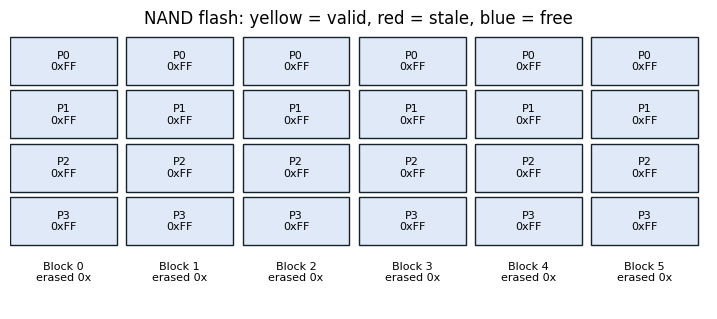

In [12]:
COLORS = {"free": "#dfe9f7", "valid": "#ffe3a8", "invalid": "#e7c9c9"}

def draw_nand(chip, ftl=None):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    for b in range(chip.NB):
        for p in range(chip.NP):
            st = chip.state[b][p]
            ax.add_patch(Rectangle((b, chip.NP - 1 - p), 0.92, 0.9, fc=COLORS[st], ec="#14222b",
                                   hatch="//" if chip.bad[b] else None))
            lba = f" L{chip.owner[b][p]}" if chip.owner[b][p] >= 0 else ""
            ax.text(b + 0.46, chip.NP - 1 - p + 0.45, f"P{p}\n0x{chip.data[b][p]:02X}{lba}", ha="center", va="center", fontsize=8)
        ax.text(b + 0.46, -0.3, f"Block {b}\nerased {chip.erase_count[b]}x" + ("\nBAD" if chip.bad[b] else ""), ha="center", va="top", fontsize=8)
    ax.set_xlim(0, chip.NB); ax.set_ylim(-1.2, chip.NP); ax.axis("off")
    ax.set_title("NAND flash: yellow = valid, red = stale, blue = free")
    plt.show()

def draw_nor(nor):
    fig, ax = plt.subplots(figsize=(9, 3))
    for s in range(nor.S):
        for i in range(nor.size):
            v = nor.data[s * nor.size + i]
            ax.add_patch(Rectangle((i, nor.S - 1 - s), 0.92, 0.9, fc=COLORS["free"] if v == ERASED else COLORS["valid"], ec="#14222b"))
            ax.text(i + 0.46, nor.S - 1 - s + 0.45, f"{s * nor.size + i}\n0x{v:02X}", ha="center", va="center", fontsize=8)
        ax.text(-0.2, nor.S - 1 - s + 0.45, f"Sector {s}\nerased {nor.erase_count[s]}x", ha="right", va="center", fontsize=8)
    ax.set_xlim(-1.6, nor.size); ax.set_ylim(0, nor.S); ax.axis("off")
    ax.set_title("NOR flash: every byte is directly addressable")
    plt.show()

def nand_stats(ftl):
    c = ftl.chip
    print(f"Host writes {ftl.host_writes} | page programs {c.programs} | block erases {c.erases} | GC runs {ftl.gc_runs} | pages copied by GC {ftl.copies}")
    print(f"Wear spread (max - min erases) {max(c.erase_count) - min(c.erase_count)} | free pages {ftl.free_pages()}")

draw_nand(NANDChip())

## Front end part 2, interactive control panel
Buttons and boxes that call the mechanisms above. This cell holds **no flash logic**, only user interface code.

If the buttons do not appear in Colab, run `from google.colab import output; output.enable_custom_widget_manager()` in a new cell and rerun this one.

In [13]:
import ipywidgets as W
from IPython.display import display, clear_output

chip = NANDChip(); ftl = FTLWithGC(chip)
nor = NORChip()
nand_out, nand_log, nor_out, nor_log = W.Output(), W.Output(), W.Output(), W.Output()

# ---------- NAND tab ----------
lba_in = W.IntText(value=0, description="LBA 0-11")
val_in = W.IntText(value=170, description="Data 0-255")
wl_box = W.Checkbox(value=True, description="Wear leveling")
btns = {n: W.Button(description=n) for n in ["Write", "Read", "10 random writes", "20 hot-spot writes", "Run GC", "Reset"]}

def nand_refresh():
    with nand_out:
        clear_output(wait=True); draw_nand(chip); nand_stats(ftl)
    with nand_log:
        clear_output(wait=True); print("\n".join(ftl.log[-12:]))

def safe(fn):
    def run(_):
        try: fn()
        except FlashError as e: ftl.say("ERROR: " + str(e))
        nand_refresh()
    return run

def nand_reset():
    global chip, ftl
    chip = NANDChip(); ftl = FTLWithGC(chip, wear_leveling=wl_box.value)
    ftl.say("Chip reset: all cells erased (0xFF)")

btns["Write"].on_click(safe(lambda: ftl.write(lba_in.value, val_in.value)))
btns["Read"].on_click(safe(lambda: ftl.read(lba_in.value)))
btns["10 random writes"].on_click(safe(lambda: [ftl.write(random.randint(0, 11), random.randint(0, 255)) for _ in range(10)]))
btns["20 hot-spot writes"].on_click(safe(lambda: [ftl.write(random.randint(0, 2), random.randint(0, 255)) for _ in range(20)]))
btns["Run GC"].on_click(safe(lambda: ftl.garbage_collect()))
btns["Reset"].on_click(safe(nand_reset))
wl_box.observe(lambda ch: setattr(ftl, "wear_leveling", ch["new"]), names="value")

nand_tab = W.VBox([W.HBox([lba_in, val_in, wl_box]), W.HBox(list(btns.values())), nand_out, W.HTML("<b>Event log</b>"), nand_log])

# ---------- NOR tab ----------
addr_in = W.IntText(value=0, description="Addr 0-31")
nval_in = W.IntText(value=60, description="Value 0-255")
nbtns = {n: W.Button(description=n) for n in ["Program byte", "Read byte", "Erase sector", "Safe update", "XIP fetch", "Reset"]}

def nor_refresh():
    with nor_out:
        clear_output(wait=True); draw_nor(nor)
        print(f"Reads {nor.reads} | byte programs {nor.programs} | sector erases {nor.erases} | total time {nor.time} units")
    with nor_log:
        clear_output(wait=True); print("\n".join(nor.log[-12:]))

def nsafe(fn):
    def run(_):
        try: fn()
        except (FlashError, IndexError) as e: nor.say("ERROR: " + str(e))
        nor_refresh()
    return run

def nor_reset():
    global nor
    nor = NORChip(); nor.say("NOR chip reset")

nbtns["Program byte"].on_click(nsafe(lambda: nor.program(addr_in.value, nval_in.value)))
nbtns["Read byte"].on_click(nsafe(lambda: nor.read(addr_in.value)))
nbtns["Erase sector"].on_click(nsafe(lambda: nor.erase_sector(addr_in.value // nor.size)))
nbtns["Safe update"].on_click(nsafe(lambda: nor.update(addr_in.value, nval_in.value)))
nbtns["XIP fetch"].on_click(nsafe(lambda: nor.fetch_sector(addr_in.value)))
nbtns["Reset"].on_click(nsafe(nor_reset))
nor_tab = W.VBox([W.HBox([addr_in, nval_in]), W.HBox(list(nbtns.values())), nor_out, W.HTML("<b>Event log</b>"), nor_log])

tabs = W.Tab(children=[nand_tab, nor_tab])
tabs.set_title(0, "NAND flash"); tabs.set_title(1, "NOR flash")
display(tabs)
nand_refresh(); nor_refresh()

## Front end part 3, flash simulator
Run this cell to open the simulator. Switch between NAND and NOR, then write, read, erase and watch the chip react.

In [14]:
from IPython.display import HTML, display

display(HTML(r"""<div id="fs">
<style>
@import url('https://fonts.googleapis.com/css2?family=Sora:wght@500;700&family=IBM+Plex+Mono:wght@400;500&display=swap');
#fs{--bg:#0c2230;--pn:#133548;--ln:#2a5b75;--tx:#e8f4f8;--mu:#8fb3c2;--free:#7fd3e6;--val:#ffb84d;--inv:#ff6f86;
font-family:'Sora',system-ui,sans-serif;color:var(--tx);background:radial-gradient(1200px 500px at 10% -10%,#17506b 0,transparent 60%),var(--bg);
border-radius:18px;padding:22px;box-sizing:border-box;max-width:1100px;margin:auto}
#fs *{box-sizing:border-box}
#fs .top{display:flex;flex-wrap:wrap;gap:14px;align-items:center;justify-content:space-between;margin-bottom:18px}
#fs h2{margin:0;font-size:clamp(22px,4vw,34px);letter-spacing:-.02em;color:var(--tx);border:0}
#fs .sub{margin:4px 0 0;color:var(--mu);font-size:14px}
#fs .tabs{display:flex;background:var(--pn);border:1px solid var(--ln);border-radius:999px;padding:4px}
#fs .tabs button{border:0;background:none;color:var(--mu);font:600 14px 'Sora',sans-serif;padding:9px 20px;border-radius:999px;cursor:pointer}
#fs .tabs button.on{background:var(--val);color:#2b1b00}
#fs .ctl{display:flex;flex-wrap:wrap;gap:10px;align-items:end;background:var(--pn);border:1px solid var(--ln);border-radius:14px;padding:14px;margin-bottom:16px}
#fs label{display:flex;flex-direction:column;gap:4px;font-size:12px;color:var(--mu)}
#fs input[type=number]{width:96px;background:#0c2230;border:1px solid var(--ln);color:var(--tx);border-radius:8px;padding:8px;font:500 15px 'IBM Plex Mono',monospace}
#fs .btn{border:1px solid var(--ln);background:#1b4660;color:var(--tx);font:600 13px 'Sora',sans-serif;padding:10px 14px;border-radius:10px;cursor:pointer;transition:transform .12s,background .12s}
#fs .btn:hover{background:#235a7a;transform:translateY(-1px)}
#fs .btn.go{background:var(--val);color:#2b1b00;border-color:var(--val)}
#fs .btn.warn{background:#5a2535;border-color:#8a3b52}
#fs .sw{flex-direction:row;align-items:center;gap:8px;color:var(--tx);font-size:13px;cursor:pointer}
#fs .sw input{accent-color:var(--val);width:18px;height:18px}
#fs .legend{display:flex;gap:16px;flex-wrap:wrap;font-size:12px;color:var(--mu);margin:0 0 10px}
#fs .legend span:before{content:"";display:inline-block;width:11px;height:11px;border-radius:3px;margin-right:6px;vertical-align:-1px;background:var(--c)}
#fs .die{display:grid;grid-template-columns:repeat(6,1fr);gap:10px;background:#0a1b27;border:1px solid var(--ln);border-radius:14px;padding:14px}
#fs .blk{background:var(--pn);border:1px solid var(--ln);border-radius:10px;padding:8px;position:relative;overflow:hidden}
#fs .bh{display:flex;justify-content:space-between;align-items:baseline;font-size:11px;color:var(--mu);margin-bottom:6px}
#fs .bh b{color:var(--tx);font-size:13px}
#fs .pg{display:grid;grid-template-columns:22px 1fr 26px;align-items:center;height:38px;margin-bottom:5px;border-radius:6px;padding:0 6px;font:500 12px 'IBM Plex Mono',monospace;border:1px solid transparent}
#fs .pg i{font-style:normal;color:#0006}#fs .pg em{font-style:normal;text-align:right;font-weight:500}
#fs .pg strong{font-weight:500;font-size:15px;text-align:center}
#fs .pg.free{background:#7fd3e61c;border-color:#7fd3e655;color:var(--free)}#fs .pg.free i{color:#7fd3e688}
#fs .pg.valid{background:var(--val);color:#2b1b00}
#fs .pg.invalid{background:repeating-linear-gradient(135deg,#ff6f8633 0 6px,#ff6f8622 6px 12px);border-color:#ff6f8688;color:#ffb3c0;text-decoration:line-through}#fs .pg.invalid i{color:#ffb3c088}
#fs .wear{height:6px;border-radius:4px;background:#0c2230;margin-top:6px;overflow:hidden}
#fs .wear div{height:100%;background:linear-gradient(90deg,var(--free),var(--val),var(--inv));background-size:var(--bs) 100%;transition:width .5s}
#fs .blk.bad{opacity:.75;filter:saturate(.4)}
#fs .blk.bad:after{content:"BAD BLOCK";position:absolute;inset:0;display:grid;place-items:center;background:#3a0f1acc;color:#ff9bb0;font-weight:700;letter-spacing:.08em;font-size:13px}
#fs .hit{animation:hit .9s ease-out}
@keyframes hit{0%{box-shadow:0 0 0 0 #fff;transform:scale(1.07);filter:brightness(1.6)}100%{box-shadow:0 0 0 14px #fff0;transform:none;filter:none}}
#fs .wipe{animation:wipe .9s ease-out}
@keyframes wipe{0%{box-shadow:0 0 0 3px var(--free),0 0 28px var(--free);filter:brightness(1.7)}100%{box-shadow:none;filter:none}}
#fs .map{display:flex;flex-wrap:wrap;gap:6px;margin:14px 0}
#fs .map b{font-size:12px;color:var(--mu);width:100%}
#fs .map span{font:500 12px 'IBM Plex Mono',monospace;background:var(--pn);border:1px solid var(--ln);border-radius:8px;padding:5px 8px;color:var(--mu)}
#fs .map span.set{color:var(--tx);border-color:var(--val)}
#fs .stats{display:grid;grid-template-columns:repeat(auto-fit,minmax(120px,1fr));gap:10px;margin:14px 0}
#fs .stat{background:var(--pn);border:1px solid var(--ln);border-radius:12px;padding:10px 12px}
#fs .stat b{display:block;font-size:26px;letter-spacing:-.02em;font-family:'IBM Plex Mono',monospace;font-weight:500}
#fs .stat span{font-size:12px;color:var(--mu)}
#fs .log{background:#0a1b27;border:1px solid var(--ln);border-radius:14px;padding:12px 14px;font:400 12.5px/1.7 'IBM Plex Mono',monospace;max-height:230px;overflow:auto}
#fs .log div{color:var(--mu)}#fs .log div:first-child{color:var(--tx)}
#fs .log .gc{color:var(--free)}#fs .log .err{color:var(--inv)}
#fs .sec{display:flex;align-items:center;gap:10px;margin-bottom:8px}
#fs .sec>small{width:92px;font-size:12px;color:var(--mu);flex:none}
#fs .bytes{display:grid;grid-template-columns:repeat(8,1fr);gap:6px;flex:1}
#fs .by{background:#7fd3e61c;border:1px solid #7fd3e655;border-radius:8px;padding:6px 2px;text-align:center;font:500 12px 'IBM Plex Mono',monospace;color:var(--free)}
#fs .by.w{background:var(--val);border-color:var(--val);color:#2b1b00}
#fs .by u{display:block;text-decoration:none;font-size:10px;opacity:.6}
#fs .by s{display:flex;justify-content:center;gap:2px;margin-top:4px;text-decoration:none}
#fs .by s i{width:6px;height:6px;border-radius:50%;border:1px solid currentColor}
#fs .by s i.z{background:currentColor}
#fs .by s{flex-wrap:nowrap}
#fs .pane{display:none}#fs .pane.on{display:block}
@media(max-width:760px){#fs .die{grid-template-columns:repeat(3,1fr)}#fs .sec{flex-direction:column;align-items:stretch}}
@media(prefers-reduced-motion:reduce){#fs .hit,#fs .wipe{animation:none}}
</style>

<div class="top">
 <div><h2>Flash Memory Simulator</h2><p class="sub">Write, rewrite and erase. Watch the controller keep up.</p></div>
 <div class="tabs"><button class="on" data-t="nand">NAND flash</button><button data-t="nor">NOR flash</button></div>
</div>

<div class="pane on" id="p-nand">
 <div class="ctl">
  <label>LBA (0–11)<input type="number" id="lba" value="0"></label>
  <label>Data (0–255)<input type="number" id="val" value="170"></label>
  <label class="sw"><input type="checkbox" id="wl" checked>Wear leveling</label>
  <button class="btn go" data-a="write">Write</button><button class="btn" data-a="read">Read</button>
  <button class="btn" data-a="rnd">10 random writes</button><button class="btn" data-a="hot">20 hot-spot writes</button>
  <button class="btn" data-a="gc">Run GC</button><button class="btn warn" data-a="reset">Reset</button>
 </div>
 <p class="legend"><span style="--c:var(--free)">Free</span><span style="--c:var(--val)">Valid</span><span style="--c:var(--inv)">Stale</span></p>
 <div class="die" id="die"></div>
 <div class="map" id="map"></div>
 <div class="stats" id="nst"></div>
 <div class="log" id="nlog"></div>
</div>

<div class="pane" id="p-nor">
 <div class="ctl">
  <label>Address (0–31)<input type="number" id="ad" value="0"></label>
  <label>Value (0–255)<input type="number" id="nv" value="60"></label>
  <button class="btn go" data-a="np">Program byte</button><button class="btn" data-a="nr">Read byte</button>
  <button class="btn" data-a="ne">Erase sector</button><button class="btn" data-a="nu">Safe update</button>
  <button class="btn" data-a="nx">XIP fetch</button><button class="btn warn" data-a="nreset">Reset</button>
 </div>
 <p class="legend"><span style="--c:var(--free)">Erased (FF)</span><span style="--c:var(--val)">Programmed</span><span style="--c:#fff">Dot = charged cell (bit 0)</span></p>
 <div class="die" style="display:block" id="nor"></div>
 <div class="stats" id="rst"></div>
 <div class="log" id="rlog"></div>
</div>

<script>
(function(){
const R=document.getElementById('fs'),$=s=>R.querySelector(s),E=255;
class FlashError extends Error{}
const hx=v=>v.toString(16).toUpperCase().padStart(2,'0'),bt=v=>v.toString(2).padStart(8,'0');
const pb=(o,n)=>{if((o&n)!==n)throw new FlashError(`Cannot program ${bt(n)} over ${bt(o)}: needs 0 → 1. Erase first.`);return n};
const rnd=(a,b)=>a+Math.floor(Math.random()*(b-a+1));
const num=(id,lo,hi,nm)=>{const v=parseInt($(id).value);if(isNaN(v)||v<lo||v>hi)throw new FlashError(`${nm} must be ${lo}..${hi}`);return v};

class NAND{constructor(){this.NB=6;this.NP=4;this.end=8;const a=(f)=>Array.from({length:6},()=>Array(4).fill(f));
 this.data=a(E);this.state=a('free');this.owner=a(-1);this.ec=Array(6).fill(0);this.bad=Array(6).fill(false);
 this.reads=this.programs=this.erases=0;this.hit=new Set();this.wipe=new Set()}
 read(b,p){this.reads++;this.hit.add(b+'.'+p);return this.data[b][p]}
 program(b,p,v,l=-1){if(this.bad[b])throw new FlashError(`Block ${b} is bad`);
  if(this.data[b][p]!==E)throw new FlashError(`Page ${b}.${p} is not erased; NAND pages are programmed once per erase`);
  this.data[b][p]=pb(this.data[b][p],v);this.state[b][p]='valid';this.owner[b][p]=l;this.programs++;this.hit.add(b+'.'+p)}
 erase(b){this.data[b]=Array(this.NP).fill(E);this.state[b]=Array(this.NP).fill('free');this.owner[b]=Array(this.NP).fill(-1);
  this.ec[b]++;this.erases++;this.wipe.add(b);if(this.ec[b]>=this.end)this.bad[b]=true}}

class FTL{constructor(c,wl=true){this.c=c;this.n=12;this.wl=wl;this.map={};this.hw=this.copies=this.gcr=0;this.log=[]}
 say(m,k=''){this.log.push({m,k})}
 free(){const c=this.c;let n=0;for(let b=0;b<c.NB;b++)if(!c.bad[b])n+=c.state[b].filter(s=>s==='free').length;return n}
 pick(ex=-1){const c=this.c;let best=null;
  for(let b=0;b<c.NB;b++){if(c.bad[b]||b===ex||!c.state[b].includes('free'))continue;
   if(best===null||(this.wl&&c.ec[b]<c.ec[best]))best=b;if(!this.wl)break}
  return best===null?null:[best,c.state[best].indexOf('free')]}
 gc(){const c=this.c;let v=null,most=0;
  for(let b=0;b<c.NB;b++){const k=c.state[b].filter(s=>s==='invalid').length;if(!c.bad[b]&&k>most){v=b;most=k}}
  if(v===null){this.say('GC: no stale pages to reclaim','gc');return false}
  this.say(`GC: victim block ${v} (${most} stale pages)`,'gc');
  for(let p=0;p<c.NP;p++)if(c.state[v][p]==='valid'){const t=this.pick(v);
   if(!t){this.say('GC failed: no room to copy','err');return false}
   const l=c.owner[v][p];c.program(t[0],t[1],c.data[v][p],l);this.map[l]=t;this.copies++;this.say(`  moved LBA ${l} to ${t[0]}.${t[1]}`,'gc')}
  c.erase(v);this.gcr++;this.say(`GC: erased block ${v} (erase count ${c.ec[v]})`+(c.bad[v]?' → now BAD':''),'gc');return true}
 write(l,v){if(l<0||l>=this.n)throw new FlashError(`LBA must be 0..${this.n-1}`);
  this.hw++;const o=this.map[l];if(o)this.c.state[o[0]][o[1]]='invalid';
  if(this.free()<=this.c.NP)this.gc();
  const t=this.pick();if(!t)throw new FlashError('Flash is full');
  this.c.program(t[0],t[1],v,l);this.map[l]=t;
  this.say(`Write LBA ${l} = 0x${hx(v)} → block ${t[0]} page ${t[1]}`+(o?` (old copy at ${o[0]}.${o[1]} now stale)`:''))}
 read(l){if(!(l in this.map))throw new FlashError(`LBA ${l} was never written`);
  const [b,p]=this.map[l],v=this.c.read(b,p);this.say(`Read LBA ${l} via map → ${b}.${p} = 0x${hx(v)}`);return v}}

class NOR{constructor(){this.S=4;this.z=8;this.data=Array(32).fill(E);this.ec=Array(4).fill(0);this.reads=this.programs=this.erases=this.time=0;this.log=[];this.hit=new Set();this.wipe=new Set()}
 say(m,k=''){this.log.push({m,k})}
 chk(a){if(a<0||a>=32)throw new FlashError('Address must be 0..31')}
 read(a){this.chk(a);this.reads++;this.time+=1;this.hit.add(a);this.say(`Read byte ${a} directly = 0x${hx(this.data[a])}`);return this.data[a]}
 program(a,v){this.chk(a);this.data[a]=pb(this.data[a],v);this.programs++;this.time+=2;this.hit.add(a);this.say(`Programmed byte ${a} = 0x${hx(v)} (${bt(v)})`)}
 erase(s){this.chk(s*this.z);const a=s*this.z;for(let i=0;i<this.z;i++)this.data[a+i]=E;this.ec[s]++;this.erases++;this.time+=50;this.wipe.add(s);this.say(`Erased sector ${s} (erase count ${this.ec[s]})`,'gc')}
 update(a,v){this.chk(a);if((this.data[a]&v)===v){this.program(a,v);return}
  const s=Math.floor(a/this.z),b=s*this.z,keep=this.data.slice(b,b+this.z);keep[a-b]=v;
  this.say(`Update at ${a} needs 0 → 1: save sector ${s}, erase, reprogram`,'gc');this.erase(s);
  keep.forEach((x,i)=>{if(x!==E)this.program(b+i,x)})}
 fetch(a){this.chk(a);const b=Math.floor(a/this.z)*this.z,vals=[];for(let i=0;i<this.z;i++)vals.push(this.read(b+i));
  this.say('XIP fetch: '+vals.map(hx).join(' '),'gc')}}

let chip,ftl,nor;
const newNand=()=>{chip=new NAND();ftl=new FTL(chip,$('#wl').checked);ftl.say('Chip reset: all cells erased (0xFF)')};
const newNor=()=>{nor=new NOR();nor.say('NOR chip reset')};
newNand();newNor();

const logHtml=a=>a.slice(-14).reverse().map(x=>`<div class="${x.k}">${x.m.replace(/ /g,'&nbsp;')}</div>`).join('');
const stat=(n,l)=>`<div class="stat"><b>${n}</b><span>${l}</span></div>`;

function drawNand(){
 let h='';
 for(let b=0;b<chip.NB;b++){
  h+=`<div class="blk${chip.bad[b]?' bad':''}${chip.wipe.has(b)?' wipe':''}"><div class="bh"><b>Block ${b}</b><span>erased ${chip.ec[b]}×</span></div>`;
  for(let p=0;p<chip.NP;p++){const s=chip.state[b][p],o=chip.owner[b][p];
   h+=`<div class="pg ${s}${chip.hit.has(b+'.'+p)?' hit':''}"><i>P${p}</i><strong>${hx(chip.data[b][p])}</strong><em>${o>=0?'L'+o:''}</em></div>`}
  h+=`<div class="wear" title="wear"><div style="width:${Math.min(100,chip.ec[b]/chip.end*100)}%;--bs:${(chip.end/Math.max(chip.ec[b],1))*100}%"></div></div></div>`}
 $('#die').innerHTML=h;
 let m='<b>Mapping table: logical address → block.page</b>';
 for(let l=0;l<12;l++){const t=ftl.map[l];m+=`<span class="${t?'set':''}">L${l} → ${t?t[0]+'.'+t[1]:'—'}</span>`}
 $('#map').innerHTML=m;
 const ec=chip.ec;
 $('#nst').innerHTML=stat(ftl.hw,'Host writes')+stat(chip.programs,'Page programs')+stat(chip.erases,'Block erases')+stat(ftl.gcr,'GC runs')+stat(ftl.copies,'Pages copied by GC')+stat(Math.max(...ec)-Math.min(...ec),'Wear spread')+stat(ftl.free(),'Free pages');
 $('#nlog').innerHTML=logHtml(ftl.log);chip.hit.clear();chip.wipe.clear();
}
function drawNor(){
 let h='';
 for(let s=0;s<nor.S;s++){
  h+=`<div class="sec${nor.wipe.has(s)?' wipe':''}"><small>Sector ${s}<br>erased ${nor.ec[s]}×</small><div class="bytes">`;
  for(let i=0;i<8;i++){const a=s*8+i,v=nor.data[a];
   h+=`<div class="by${v!==E?' w':''}${nor.hit.has(a)?' hit':''}"><u>${a}</u>${hx(v)}<s>${bt(v).split('').map(c=>`<i class="${c==='0'?'z':''}"></i>`).join('')}</s></div>`}
  h+='</div></div>'}
 $('#nor').innerHTML=h;
 $('#rst').innerHTML=stat(nor.reads,'Reads')+stat(nor.programs,'Byte programs')+stat(nor.erases,'Sector erases')+stat(nor.time,'Total time units');
 $('#rlog').innerHTML=logHtml(nor.log);nor.hit.clear();nor.wipe.clear();
}

const acts={
 write:()=>ftl.write(num('#lba',0,11,'LBA'),num('#val',0,255,'Data')),
 read:()=>ftl.read(num('#lba',0,11,'LBA')),
 rnd:()=>{for(let i=0;i<10;i++)ftl.write(rnd(0,11),rnd(0,255))},
 hot:()=>{for(let i=0;i<20;i++)ftl.write(rnd(0,2),rnd(0,255))},
 gc:()=>ftl.gc(),
 reset:()=>newNand(),
 np:()=>nor.program(num('#ad',0,31,'Address'),num('#nv',0,255,'Value')),
 nr:()=>nor.read(num('#ad',0,31,'Address')),
 ne:()=>nor.erase(Math.floor(num('#ad',0,31,'Address')/8)),
 nu:()=>nor.update(num('#ad',0,31,'Address'),num('#nv',0,255,'Value')),
 nx:()=>nor.fetch(num('#ad',0,31,'Address')),
 nreset:()=>newNor()};

R.addEventListener('click',e=>{
 const t=e.target.closest('[data-t]');
 if(t){R.querySelectorAll('.tabs button').forEach(x=>x.classList.toggle('on',x===t));
  $('#p-nand').classList.toggle('on',t.dataset.t==='nand');$('#p-nor').classList.toggle('on',t.dataset.t==='nor');return}
 const a=e.target.closest('[data-a]');if(!a)return;
 const isN=a.dataset.a[0]==='n',L=isN?nor:ftl;
 try{acts[a.dataset.a]()}catch(err){if(!(err instanceof FlashError))throw err;(isN?nor:ftl).say('ERROR: '+err.message,'err')}
 isN?drawNor():drawNand()});
$('#wl').addEventListener('change',e=>{ftl.wl=e.target.checked});
drawNand();drawNor();
})();
</script>
</div>
"""))


# Part E: Comparison and conclusion

## NAND vs NOR comparison

In [15]:
pd.set_option("display.max_colwidth", None)
pd.DataFrame({
    "Feature": ["Cell connection", "Read access", "Program unit", "Erase unit", "Program mechanism", "Read speed",
                "Write and erase speed", "Density and cost per bit", "Needs mapping and GC", "Execute in place", "Typical use"],
    "NAND": ["Series strings", "Page at a time", "Page", "Block", "Fowler-Nordheim tunnelling", "Slower",
             "Faster", "High density, cheaper", "Yes", "No", "SSD, USB drive, SD card, phone"],
    "NOR": ["Parallel cells", "Random, byte level", "Byte or word", "Sector", "Channel hot-electron injection", "Faster",
            "Slower", "Lower density, costlier", "Usually no", "Yes", "Firmware, BIOS, boot code"],
}).set_index("Feature")

,NAND,NOR
Feature,,
Cell connection,Series strings,Parallel cells
Read access,Page at a time,"Random, byte level"
Program unit,Page,Byte or word
Erase unit,Block,Sector
Program mechanism,Fowler-Nordheim tunnelling,Channel hot-electron injection
Read speed,Slower,Faster
Write and erase speed,Faster,Slower
Density and cost per bit,"High density, cheaper","Lower density, costlier"
Needs mapping and GC,Yes,Usually no
